# Sanity checks of simulation and configuration files

This notebook loads the REBOUND simulation file that contains all of the asteroids in the target family. 

It then plots the asteroid orbits in various planes as a sanity check on the data.  


In [2]:
import rebound as rb
import pandas as pd
import numpy as np
from datetime import datetime
import time
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline


In [10]:
family_name = "euterpe"

project_dir = Path(f'../../{family_name}_ast/')
plot_dir = project_dir / 'plots'

family_sim = project_dir / 'inputs/family_sim.bin'
family = rb.Simulation(str(family_sim.resolve()))
print(f'Number of particles in simulation:{len(family.particles)}, Number active:{family.N_active} Number of test particles {len(family.particles)-family.N_active}')

assingments = project_dir / 'inputs/family_assignments.h5'
family_particles = pd.read_hdf(assingments)
family_particles.head()


Number of particles in simulation:535, Number active:9 Number of test particles 526


,ast_name,particle_number
0,27,10
1,3014,11
2,3473,12
3,5002,13
4,5009,14


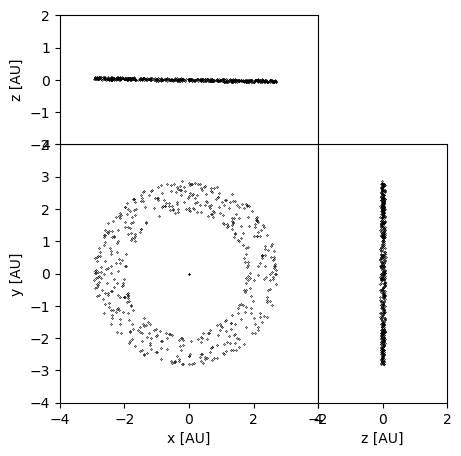

In [13]:
parts = range(9, 535)
rb.OrbitPlotSet(family, unitlabel="[AU]", particles = parts, orbit_style=None, periastron=True, xlim=[-4,4], ylim=[-4,4], lw=0.001)

In [14]:
max_a = 0
max_e = 0
max_inc = 0
min_a = 0
min_e = 0
min_inc = 0

orbital_parameters = np.zeros([len(family.particles)-9, 11])

for i_p, part in enumerate(family.particles[9:]):
    orbital_parameters[i_p][0] = part.x
    orbital_parameters[i_p][1] = part.y
    orbital_parameters[i_p][2] = part.z
    orbital_parameters[i_p][3] = part.vx
    orbital_parameters[i_p][4] = part.vy
    orbital_parameters[i_p][5] = part.vz
    orbital_parameters[i_p][6] = part.a
    orbital_parameters[i_p][7] = part.e
    orbital_parameters[i_p][8] = part.inc
    orbital_parameters[i_p][9] = part.omega
    orbital_parameters[i_p][10] = part.Omega

orb_params_cols = ['x', 'y', 'z','vx', 'vy', 'vz', 'a', 'e', 'inc', 'omega', 'Omega']
orb_params_df = pd.DataFrame(orbital_parameters, columns=orb_params_cols)

orb_params_df['inc_deg'] = np.degrees(np.arcsin(orb_params_df['inc']))
    

In [15]:
orb_params_df.describe()

,x,y,z,vx,vy,vz,a,e,inc,omega,Omega,inc_deg
count,526.000000,526.000000,526.000000,526.000000,526.000000,526.000000,526.000000,526.000000,526.000000,526.000000,526.000000,526.000000
mean,-0.152581,0.179709,0.003066,-0.040524,0.000169,0.000870,2.359627,0.192404,0.020617,3.174051,1.484165,1.181400
std,1.710106,1.732487,0.038494,0.461879,0.452197,0.010270,0.028884,0.029120,0.009170,1.837032,0.892770,0.525529
min,-2.929757,-2.802867,-0.081383,-0.776118,-0.764088,-0.024599,2.270208,0.137192,0.000953,0.011097,-3.113647,0.054583
25%,-1.793238,-1.519931,-0.026690,-0.466981,-0.439161,-0.006309,2.337475,0.163755,0.013519,1.473586,0.895466,0.774620
50%,-0.152750,0.234504,0.004042,-0.079625,-0.011411,0.001330,2.359539,0.194020,0.022720,3.326117,1.555185,1.301855
75%,1.406948,1.834613,0.031636,0.416198,0.417129,0.008518,2.381148,0.219906,0.028313,4.726633,2.179981,1.622416
max,2.698456,2.872509,0.090648,0.777578,0.827592,0.025024,2.426930,0.240268,0.036518,6.238751,3.128297,2.092776


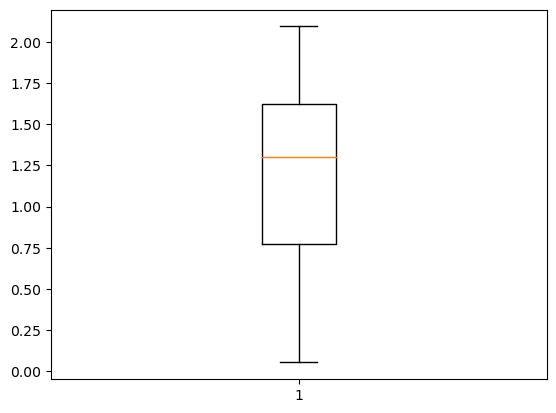

In [16]:
plt.boxplot(orb_params_df.inc_deg)
plt.show()

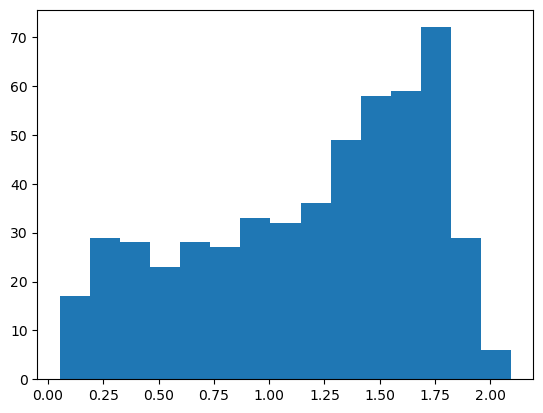

In [17]:
plt.hist(orb_params_df.inc_deg, bins=15)
plt.show()


In [18]:

orb_params_df[(orb_params_df.a <= 2.1) | (orb_params_df.a >= 3.9)].sort_values('a')

orb_params_df[(orb_params_df.e >= 0.3)].sort_values('e')

orb_params_df[(orb_params_df.inc >= 0.5)].sort_values('inc_deg')

,x,y,z,vx,vy,vz,a,e,inc,omega,Omega,inc_deg


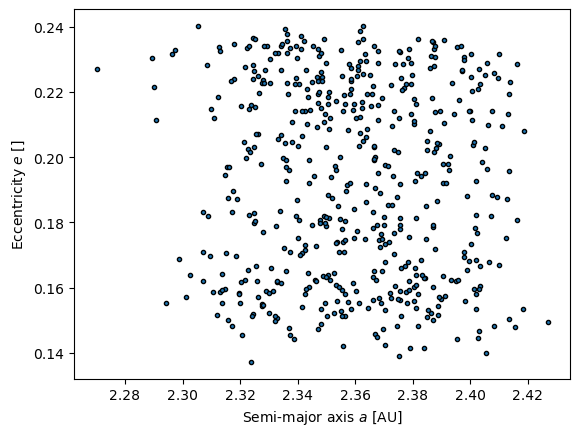

In [19]:
plt.scatter(data=orb_params_df, x='a',y='e', edgecolors='black', marker=".")
plt.xlabel("Semi-major axis $a$ [AU]")
plt.ylabel("Eccentricity $e$ []")
plt.show()

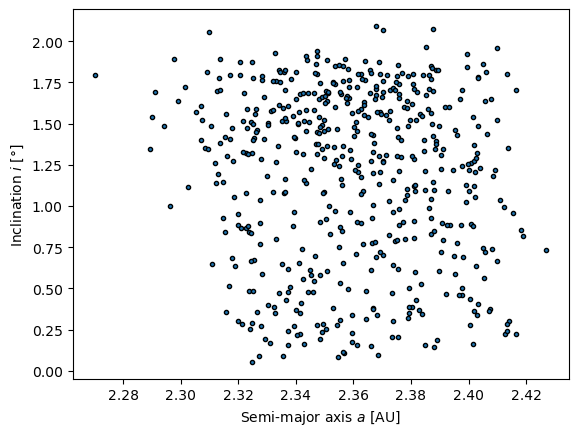

In [20]:
plt.scatter(data=orb_params_df, x='a',y='inc_deg', edgecolors='black', marker=".")
plt.xlabel("Semi-major axis $a$ [AU]")
plt.ylabel("Inclination $i$ [$\degree$]")
plt.show()

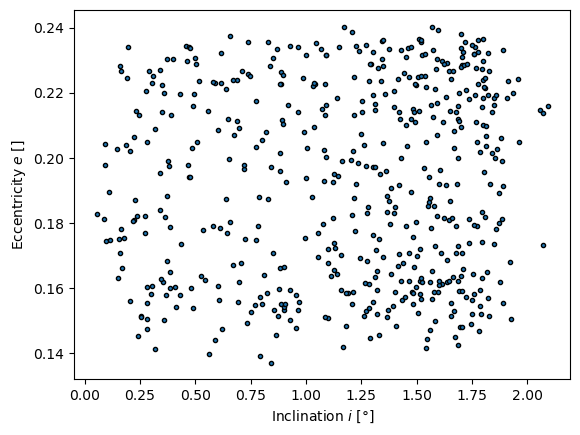

In [21]:
plt.scatter(data=orb_params_df, x='inc_deg',y='e', edgecolors='black', marker=".")
plt.xlabel("Inclination $i$ [$\degree$]")
plt.ylabel("Eccentricity $e$ []")
plt.show()

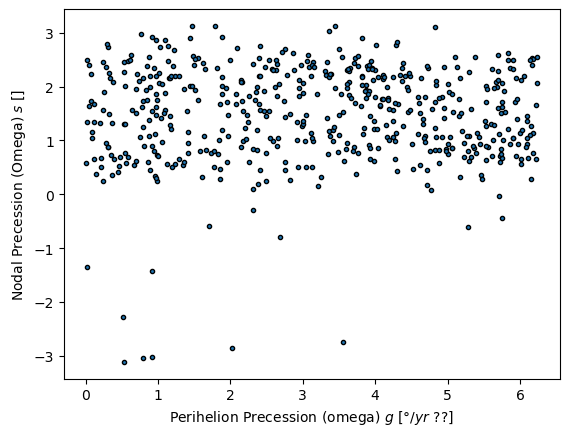

In [22]:
plt.scatter(data=orb_params_df, x='omega',y='Omega', edgecolors='black', marker=".")
plt.xlabel("Perihelion Precession (omega) $g$ [$\degree/yr$ ??]")
plt.ylabel("Nodal Precession (Omega) $s$ []")
plt.show()